   # Lab 1 — Intro to Behavioral TV Data
   Name: Valentyna Tkachenko | Group: КМ-41

## Setup

In [42]:
!pip install kagglehub -q
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

for name, df in [("programs", programs), ("viewings", viewings),
                 ("daily_weights", daily_weights),
                 ("viewer_attributes", viewer_attributes), ("attributes", attributes)]:
    print(name, df.shape)

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.
programs (5841, 15)
viewings (1001885, 9)
daily_weights (407561, 4)
viewer_attributes (104679, 3)
attributes (58, 5)


In [43]:
va = viewer_attributes.merge(attributes[["attr_id", "attr_group", "attr_name"]],
                             on="attr_id", how="left")
print("Codes without a name:", va.attr_name.isna().sum())
display(va.head())

Codes without a name: 0


,respondent_id,attr_id,value,attr_group,attr_name
0,10000100,104,NaN,Respondent type,H: household record (id ending 00)
1,10000100,802,NaN,Household size,2 persons
2,10000100,815,NaN,Household income,$100k-$150k
3,10000100,822,NaN,Children in household,No children under 18
4,10000100,833,NaN,TV reception,Telco / fiber


## Task 1.1 — Panel and universe

In [44]:
dw_h = daily_weights[daily_weights.resp_type == "H"]
dw_p = daily_weights[daily_weights.resp_type.isin(["R", "L"])]

hh_per_day = dw_h.groupby("broadcast_date")["respondent_id"].nunique()
pers_per_day = dw_p.groupby("broadcast_date")["respondent_id"].nunique()
hh_w_per_day = dw_h.groupby("broadcast_date")["weight"].sum()
pers_w_per_day = dw_p.groupby("broadcast_date")["weight"].sum()

print("Telecasts:", programs["telecast_id"].nunique())
print("Programs:", programs["program_name"].nunique())
print("Networks:", programs["network_code"].nunique())
print("Households in panel:", dw_h["respondent_id"].nunique())
print("Persons in panel:", dw_p["respondent_id"].nunique())
print("Households in-tab, average day:", round(hh_per_day.mean(), 1))
print("Persons in-tab, average day:", round(pers_per_day.mean(), 1))
print("US TV households represented, average day (M):", f"{hh_w_per_day.mean() / 1e6:.2f}")
print("US persons represented, average day (M):", f"{pers_w_per_day.mean() / 1e6:.2f}")

codes = {104: "H", 101: "R", 102: "L"}
rec = (viewer_attributes[viewer_attributes.attr_id.isin(codes)]
       .assign(t=lambda d: d.attr_id.map(codes))[["respondent_id", "t"]].drop_duplicates())
print(rec.t.value_counts())
print("Not in-tab in October:")
print(rec[~rec.respondent_id.isin(daily_weights.respondent_id)].t.value_counts())

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28
t
R    10095
H     4256
L      121
Name: count, dtype: int64
Not in-tab in October:
t
R    6
H    2
Name: count, dtype: int64


**Answer:**
The data has 5,841 telecasts of 246 distinct programs on 10 networks. In October 4,254 households and 10,210 persons were in-tab at least once, but on an average day only about 3,878 households and 9,269 persons were measured, because panel members join, leave or miss days. Their weights add up to 125.80 M TV households and 317.28 M persons, i.e. the full US universe. viewer_attributes lists 2 more households and 6 more persons (4,256 H; 10,095 R + 121 L): these records have attributes but were never in-tab in October (e.g. they left the panel before the month or joined after it, or their meter failed all month), so they have no weights and cannot be projected.

## Task 1.2 — Average audience by hour of day

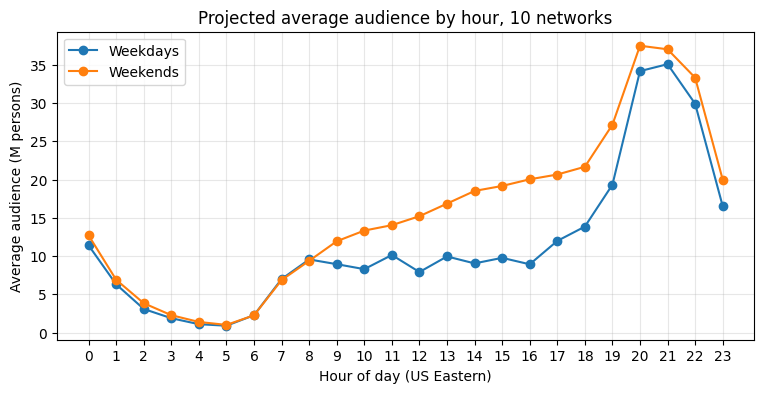

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [45]:
import numpy as np

v = viewings[viewings.resp_type.isin(["R", "L"])].copy()
v["start_ts"] = pd.to_datetime(v["start_ts"])
v["end_ts"] = pd.to_datetime(v["end_ts"])

h0 = v.start_ts.dt.floor("h")
h1 = (v.end_ts - pd.Timedelta(seconds=1)).dt.floor("h")
n = (((h1 - h0) / pd.Timedelta("1h")).round().astype(int) + 1).clip(lower=1).values
idx = np.repeat(np.arange(len(v)), n)
k = np.arange(len(idx)) - np.repeat(np.cumsum(n) - n, n)
d = v.iloc[idx].reset_index(drop=True)
d["hour_start"] = h0.values[idx] + pd.to_timedelta(k, unit="h")
seg_start = d[["start_ts", "hour_start"]].max(axis=1)
seg_end = pd.concat([d.end_ts, d.hour_start + pd.Timedelta("1h")], axis=1).min(axis=1)
d["minutes"] = (seg_end - seg_start).dt.total_seconds() / 60

d["bdate"] = (d.hour_start - pd.Timedelta("6h")).dt.normalize()
days = pd.to_datetime(pd.Series(daily_weights.broadcast_date.unique()))
d = d[d.bdate.isin(days)]
d["hour"] = d.hour_start.dt.hour
d["weekend"] = d.bdate.dt.dayofweek >= 5
d["wmin"] = d.minutes * d.weight

n_days = {False: (days.dt.dayofweek < 5).sum(), True: (days.dt.dayofweek >= 5).sum()}
aud = d.groupby(["weekend", "hour"]).wmin.sum().unstack(0).fillna(0)
aud[False] = aud[False] / 60 / n_days[False] / 1e6
aud[True] = aud[True] / 60 / n_days[True] / 1e6

plt.figure(figsize=(9, 4))
plt.plot(aud.index, aud[False], marker="o", label="Weekdays")
plt.plot(aud.index, aud[True], marker="o", label="Weekends")
plt.xticks(range(24)); plt.xlabel("Hour of day (US Eastern)")
plt.ylabel("Average audience (M persons)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Projected average audience by hour, 10 networks")
plt.show()

print("Peak hour, weekdays:", aud[False].idxmax())
print("Peak hour, weekends:", aud[True].idxmax())

**Answer:**
On weekdays the audience of the ten networks peaks at 21:00 (about 35 M persons), on weekends at 20:00 (about 37 M). The weekend curve is higher in almost every hour from 09:00 to midnight: in the daytime (10:00–16:00) the weekend audience is roughly 13–20 M versus 8–10 M on weekdays, because people are at home instead of at work or school, and the evening peak is a bit higher and one hour earlier. The two curves are very similar in the night and early morning (00:00–08:00), when the audience is small and the routines are similar. On weekdays the audience is nearly flat during the day and rises sharply only in the evening, from about 19:00, i.e. TV is mostly a prime-time medium.

## Task 1.3 — Session length

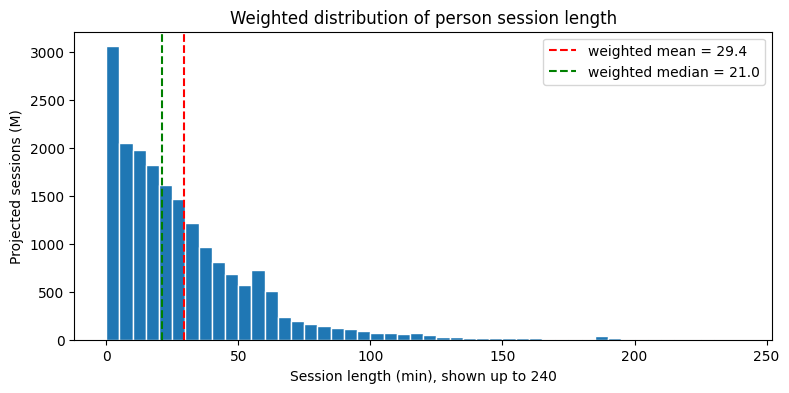

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0
Share of projected sessions longer than 240 min: 0.001
Longest session (min): 388.0


In [46]:
p = viewings[viewings.resp_type.isin(["R", "L"])].copy()
p["len_min"] = (pd.to_datetime(p.end_ts) - pd.to_datetime(p.start_ts)).dt.total_seconds() / 60

x = p.len_min.values
w = p.weight.values.astype(float)

mean_len = (x * w).sum() / w.sum()
order = np.argsort(x)
cw = np.cumsum(w[order])
median_len = x[order][np.searchsorted(cw, 0.5 * cw[-1])]

plt.figure(figsize=(9, 4))
plt.hist(x, bins=np.arange(0, 241, 5), weights=w / 1e6, edgecolor="white")
plt.axvline(mean_len, color="red", ls="--", label=f"weighted mean = {mean_len:.1f}")
plt.axvline(median_len, color="green", ls="--", label=f"weighted median = {median_len:.1f}")
plt.xlabel("Session length (min), shown up to 240")
plt.ylabel("Projected sessions (M)")
plt.title("Weighted distribution of person session length")
plt.legend(); plt.show()

print("Session length, weighted mean (min):", f"{mean_len:.1f}")
print("Session length, weighted median (min):", f"{median_len:.1f}")
print("Share of projected sessions longer than 240 min:", f"{w[x > 240].sum() / w.sum():.3f}")
print("Longest session (min):", x.max())

**Answer:**
The weighted mean session length is 29.4 min and the weighted median is 21.0 min. The distribution is strongly right-skewed: most sessions are short (channel surfing, a few minutes of a show), while a minority of long sessions (a full hour-long program, a movie or a game, up to several hours) pull the mean up but barely move the median. In a client deck I would show the median (21 min) as the “typical” session, because it is not distorted by a few very long sessions, and mention the mean only when total viewing time matters, since the mean times the number of sessions gives the total minutes watched.

## Task 2 — Program reach curve

In [47]:
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])

tel = programs[(programs.network_code == "CBS") &
               programs.program_name.str.contains("Evening News", case=False)].copy()
tel["start_ts"] = pd.to_datetime(tel.start_ts)
tel["end_ts"] = pd.to_datetime(tel.end_ts)
tel = tel.sort_values("start_ts")
print(tel.program_name.value_counts())
print(tel.start_ts.dt.day_name().value_counts())

vw = viewings[(viewings.network_code == "CBS") & viewings.resp_type.isin(["H", "R", "L"])][
    ["respondent_id", "resp_type", "start_ts", "end_ts"]].copy()
vw["start_ts"] = pd.to_datetime(vw.start_ts)
vw["end_ts"] = pd.to_datetime(vw.end_ts)

x = vw.merge(tel[["telecast_id", "broadcast_date", "start_ts", "end_ts"]]
             .rename(columns={"start_ts": "t0", "end_ts": "t1"}), how="cross")
x = x[(x.start_ts < x.t1) & (x.end_ts > x.t0)]
x["overlap_min"] = ((x[["end_ts", "t1"]].min(axis=1) - x[["start_ts", "t0"]].max(axis=1))
                    .dt.total_seconds() / 60)
x = x[x.overlap_min >= 1]

watched = (x[["telecast_id", "respondent_id", "resp_type", "broadcast_date"]]
           .drop_duplicates()
           .merge(daily_weights[["respondent_id", "broadcast_date", "weight"]],
                  on=["respondent_id", "broadcast_date"], how="inner"))
print("viewers found:", len(x[["telecast_id", "respondent_id"]].drop_duplicates()),
      "| with weight that day:", len(watched))

den_hh = daily_weights[daily_weights.resp_type == "H"].groupby("broadcast_date").weight.sum()
den_p = daily_weights[daily_weights.resp_type.isin(["R", "L"])].groupby("broadcast_date").weight.sum()
num_hh = watched[watched.resp_type == "H"].groupby("telecast_id").weight.sum()
num_p = watched[watched.resp_type.isin(["R", "L"])].groupby("telecast_id").weight.sum()

res = tel.set_index("telecast_id")[["broadcast_date", "start_ts"]].copy()
res["hh_rating"] = num_hh.reindex(res.index).fillna(0) / res.broadcast_date.map(den_hh) * 100
res["p2_rating"] = num_p.reindex(res.index).fillna(0) / res.broadcast_date.map(den_p) * 100
res["audience_M"] = num_p.reindex(res.index).fillna(0) / 1e6
display(res.round(2))

print("Telecasts of the program:", len(res))
print("Average household rating (%):", f"{res.hh_rating.mean():.1f}")
print("Average P2+ rating (%):", f"{res.p2_rating.mean():.1f}")
print("Average projected audience (M):", f"{res.audience_M.mean():.2f}")

program_name
CBS Evening News    23
Name: count, dtype: int64
start_ts
Tuesday      5
Wednesday    5
Thursday     5
Friday       4
Monday       4
Name: count, dtype: int64
viewers found: 5730 | with weight that day: 5730


,broadcast_date,start_ts,hh_rating,p2_rating,audience_M
telecast_id,,,,,
1003837,2024-10-01,2024-10-01 18:30:00,3.47,1.67,5.28
1003857,2024-10-02,2024-10-02 18:30:00,3.07,1.48,4.68
1003877,2024-10-03,2024-10-03 18:30:00,2.99,1.47,4.68
1003896,2024-10-04,2024-10-04 18:30:00,3.00,1.51,4.81
1003936,2024-10-07,2024-10-07 18:30:00,3.06,1.52,4.83
1003952,2024-10-08,2024-10-08 18:30:00,3.17,1.57,4.97
1003970,2024-10-09,2024-10-09 18:30:00,2.98,1.48,4.70
1003985,2024-10-10,2024-10-10 18:30:00,3.38,1.62,5.13
1004001,2024-10-11,2024-10-11 18:30:00,3.09,1.48,4.69


Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93


Persons without age: 0


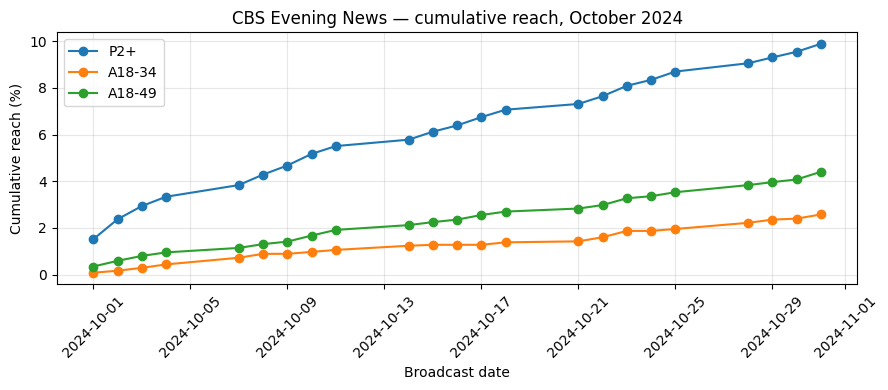

Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [48]:
mw = (daily_weights[daily_weights.resp_type.isin(["R", "L"])]
      .groupby("respondent_id").weight.mean().rename("mw").to_frame())
age = (viewer_attributes[viewer_attributes.attr_id == 300]
       .drop_duplicates("respondent_id").set_index("respondent_id")["value"].rename("age"))
pers = mw.join(age, how="left")
print("Persons without age:", pers.age.isna().sum())

masks = {"P2+": pd.Series(True, index=pers.index),
         "A18-34": pers.age.between(18, 34),
         "A18-49": pers.age.between(18, 49)}
total = {g: pers.mw[m].sum() for g, m in masks.items()}

order = res.sort_values("start_ts").index.tolist()
people_by_tel = (watched[watched.resp_type.isin(["R", "L"])]
                 .groupby("telecast_id").respondent_id.apply(set))
seen = set()
reach = {g: [] for g in masks}
for t in order:
    seen |= people_by_tel.get(t, set())
    in_seen = pers.index.isin(seen)
    for g, m in masks.items():
        reach[g].append(pers.mw[m & in_seen].sum() / total[g] * 100)

plt.figure(figsize=(9, 4))
dates = res.loc[order, "broadcast_date"]
for g in masks:
    plt.plot(dates, reach[g], marker="o", label=g)
plt.ylabel("Cumulative reach (%)"); plt.xlabel("Broadcast date")
plt.title("CBS Evening News — cumulative reach, October 2024")
plt.legend(); plt.grid(alpha=.3); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

print("Final reach P2+ (%):", f"{reach['P2+'][-1]:.1f}")
print("Final reach A18-34 (%):", f"{reach['A18-34'][-1]:.1f}")
print("Final reach A18-49 (%):", f"{reach['A18-49'][-1]:.1f}")

**Answer:**
Each telecast of CBS Evening News has a P2+ rating of only about 1.6%, but the cumulative reach grows steadily and reaches 9.9% of P2+ after the 23 telecasts of October. The rating counts the people who watch one particular evening, while reach counts everyone who watched at least once; every night some people who have not seen the program yet tune in, so reach keeps growing, but more slowly with time, because a larger share of each night’s audience are repeat viewers. The ratio of the summed ratings (23 × 1.6 ≈ 37 rating points) to the final reach (9.9%) gives an average frequency of roughly 3.7 telecasts per viewer. The program reaches adults 18–49 much less well (4.4%) and adults 18–34 least of all (2.6%) than the population as a whole (9.9%), which means that its audience is concentrated among older people (50+), as one would expect for a network evening news program. This matches what I know about this genre: its viewers are mostly older adults, so it is an inefficient buy for an advertiser targeting young adults.

## Task 3 — Program frequency

program_name
The Young and the Restless    23
Name: count, dtype: int64
Telecasts: 23 | repeats: 0
start_ts
Tuesday      5
Wednesday    5
Thursday     5
Friday       4
Monday       4
Name: count, dtype: int64
Viewers without monthly weight: 0


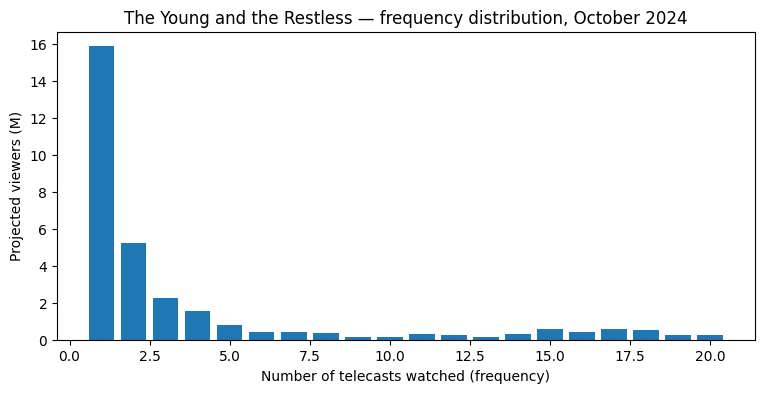

Projected viewers (M): 30.80
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704
80th percentile of frequency: 4


In [49]:
def persons_who_watched(tel, network):
    """Persons (R, L) with >= 1 minute of overlap with each telecast."""
    tel = tel.copy()
    tel["t0"] = pd.to_datetime(tel.start_ts)
    tel["t1"] = pd.to_datetime(tel.end_ts)
    vw = viewings[(viewings.network_code == network) & viewings.resp_type.isin(["R", "L"])][
        ["respondent_id", "start_ts", "end_ts"]].copy()
    vw["start_ts"] = pd.to_datetime(vw.start_ts)
    vw["end_ts"] = pd.to_datetime(vw.end_ts)
    x = vw.merge(tel[["telecast_id", "t0", "t1"]], how="cross")
    x = x[(x.start_ts < x.t1) & (x.end_ts > x.t0)]
    ov = (x[["end_ts", "t1"]].min(axis=1) - x[["start_ts", "t0"]].max(axis=1)).dt.total_seconds() / 60
    return x[ov >= 1][["telecast_id", "respondent_id"]].drop_duplicates()

yr = programs[(programs.network_code == "CBS") &
              programs.program_name.str.contains("Young and the Restless", case=False)].copy()
print(yr.program_name.value_counts())
print("Telecasts:", len(yr), "| repeats:", yr.is_repeat.sum())
print(pd.to_datetime(yr.start_ts).dt.day_name().value_counts())

pw = persons_who_watched(yr, "CBS")
freq = pw.groupby("respondent_id").size().rename("freq").to_frame().join(mw)
print("Viewers without monthly weight:", freq.mw.isna().sum())

f, w = freq.freq.values, freq.mw.values
total_w = w.sum()
avg_f = (f * w).sum() / total_w

def wquantile(values, weights, q):
    o = np.argsort(values)
    cw = np.cumsum(weights[o])
    return values[o][np.searchsorted(cw, q * cw[-1])]

med_f = wquantile(f, w, 0.5)
p80 = wquantile(f, w, 0.8)
loyal = f >= p80
share_loyal = (f[loyal] * w[loyal]).sum() / (f * w).sum()

dist = freq.groupby("freq").mw.sum() / 1e6
plt.figure(figsize=(9, 4))
plt.bar(dist.index, dist.values)
plt.xlabel("Number of telecasts watched (frequency)")
plt.ylabel("Projected viewers (M)")
plt.title("The Young and the Restless — frequency distribution, October 2024")
plt.show()

print("Projected viewers (M):", f"{total_w / 1e6:.2f}")
print("Average frequency (weighted):", f"{avg_f:.2f}")
print("Median frequency (weighted):", f"{med_f:.0f}")
print("Share of views from the most loyal viewers:", f"{share_loyal:.3f}")
print("80th percentile of frequency:", p80)

**Answer:**
About 30.8 M people watched at least one of the 23 telecasts of The Young and the Restless in October. The average frequency is 3.63 telecasts, but the weighted median is only 1: roughly half of the viewers watched the program just once. The distribution has two groups: a large group of occasional viewers (1–3 telecasts) and a much smaller group of loyal viewers who watched almost every day (14–20 telecasts). The viewers with frequency at or above the weighted 80th percentile (4 telecasts) are a minority of the audience, but they generate 70.4% of all projected views. So the average frequency is not a fair summary (“the average can lie”): hardly anyone actually watches 3.6 telecasts, the mean mixes two very different audiences, and it is pulled up by the loyal minority. A better description is the full distribution, or at least the median together with the share of views from the loyal viewers.

## Task 4 — Networks by age and gender

In [50]:
display(attributes[attributes.attr_id.isin([201, 202])])

sex = (viewer_attributes[viewer_attributes.attr_id.isin([201, 202])]
       .drop_duplicates("respondent_id").set_index("respondent_id")["attr_id"]
       .map({201: "M", 202: "W"}).rename("sex"))
demo = age.to_frame().join(sex, how="left")
print("Persons without sex:", demo.sex.isna().sum())

p = viewings[viewings.resp_type.isin(["R", "L"])][
    ["respondent_id", "network_code", "start_ts", "end_ts", "weight"]].copy()
p["minutes"] = (pd.to_datetime(p.end_ts) - pd.to_datetime(p.start_ts)).dt.total_seconds() / 60
p = p.join(demo, on="respondent_id")
p["wmin"] = p.minutes * p.weight
p["band"] = pd.cut(p.age, [17, 34, 54, 120], labels=["18-34", "35-54", "55+"])
p["aud"] = p.sex.astype(str) + p.band.astype(str)

six = ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]
mins = p[p.aud.isin(six)].groupby(["aud", "network_code"]).wmin.sum().unstack(0)[six] / 1e6

for a in six:
    print(f"Top 5 networks, {a} (projected minutes, M)")
    display(mins[a].sort_values(ascending=False).head(5).round(1).to_frame("proj_minutes_M"))

young = (p.age >= 18) & (p.age <= 34)
share = pd.DataFrame({
    "weighted": p[young].groupby("network_code").wmin.sum() / p.groupby("network_code").wmin.sum(),
    "raw": p[young].groupby("network_code").minutes.sum() / p.groupby("network_code").minutes.sum(),
}).sort_values("weighted", ascending=False)
display(share.round(3))

print("Youngest network:", share.weighted.idxmax())
print("Oldest network:", share.weighted.idxmin())

,attr_id,attr_group,attr_name,value_type,applies_to
4,201,Sex,Male,flag,"R,L,S"
5,202,Sex,Female,flag,"R,L,S"


Persons without sex: 0
Top 5 networks, M18-34 (projected minutes, M)


,proj_minutes_M
network_code,
FOX,4386.6
NBC,3910.4
CBS,3044.3
ABC,3010.8
FX,1474.0


Top 5 networks, W18-34 (projected minutes, M)


,proj_minutes_M
network_code,
FOX,4574.4
NBC,4527.6
ABC,3504.9
CBS,2811.2
FX,1383.5


...

,proj_minutes_M
network_code,
CBS,38274.0
NBC,34267.4
FOX,30878.5
ABC,30793.3
FNC,27903.7


Top 5 networks, W55+ (projected minutes, M)


,proj_minutes_M
network_code,
CBS,47120.3
NBC,41391.9
ABC,38840.0
FOX,36914.7
FNC,31450.7


,weighted,raw
network_code,,
FX,0.266,0.232
BRAVO,0.148,0.127
FOX,0.082,0.075
FOOD,0.078,0.071
NBC,0.073,0.068
ABC,0.064,0.060
HGTV,0.058,0.052
CBS,0.051,0.050
HIST,0.048,0.044


Youngest network: FX
Oldest network: FNC


In [51]:
young_p = pers.age.between(18, 34)
print("Share of 18-34 among panel persons (raw):", f"{young_p.mean():.3f}")
print("Share of 18-34 among persons (weighted):", f"{pers.mw[young_p].sum() / pers.mw.sum():.3f}")

Share of 18-34 among panel persons (raw): 0.197
Share of 18-34 among persons (weighted): 0.229


**Answer:**
FX has the youngest audience (26.6% of its projected minutes come from viewers aged 18–34) and Fox News the oldest (1.8%). In absolute projected minutes, the 55+ groups are led by CBS and NBC (followed by FOX and ABC), while the 18–34 groups are led by FOX and NBC (followed by CBS and ABC); FX is the youngest network by share but only 5th in absolute minutes among 18–34. The share of 18–34 minutes is higher with weights than without them for every network (for example FX 0.266 vs 0.232), which means that young people are under-represented in the panel: each young panelist stands for more Americans than the average panelist and therefore gets a larger weight. Indeed, adults aged 18–34 are 19.7% of the panel persons but 22.9% of the US population when weighted. The ranking of the networks by age is the same with and without weights, but if we reported raw panel numbers to a client, we would understate the 18–34 share of every network (by about 2–14% in relative terms), and the raw minutes describe only the ~10,000 panelists, not the US population, so they could not be compared with real audience sizes or rating points.

**Bonus answer:**
Fox News is the oldest network (only about 2% of its minutes come from 18–34), so I would not pitch it as a young network. I would sell it as a complement: buy FX or Bravo for the bulk of 18–34 reach, and add Fox News for the young adults who do watch it, in a highly engaged live-news environment (October 2024 is the election season), with the large loyal older audience as an extra for households where several generations decide together.